Customer Shopping Behavior Analysis

In [1]:
#libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
print(sqlite3.sqlite_version)

3.50.4


In [2]:
df = pd.read_csv(r"D:\Data Analyst Project Related Material\Project 3\customer_shopping_behavior.csv")

In [5]:
df.head()

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


In [4]:
df.info

<bound method DataFrame.info of       Customer ID  Age  Gender Item Purchased     Category  \
0               1   55    Male         Blouse     Clothing   
1               2   19    Male        Sweater     Clothing   
2               3   50    Male          Jeans     Clothing   
3               4   21    Male        Sandals     Footwear   
4               5   45    Male         Blouse     Clothing   
...           ...  ...     ...            ...          ...   
3895         3896   40  Female         Hoodie     Clothing   
3896         3897   52  Female       Backpack  Accessories   
3897         3898   46  Female           Belt  Accessories   
3898         3899   44  Female          Shoes     Footwear   
3899         3900   52  Female        Handbag  Accessories   

      Purchase Amount (USD)       Location Size      Color  Season  \
0                        53       Kentucky    L       Gray  Winter   
1                        64          Maine    L     Maroon  Winter   
2            

In [6]:
df.describe(include = 'all')

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
count,3900.000000,3900.000000,3900,3900,3900,3900.000000,3900,3900,3900,3900,3863.000000,3900,3900,3900,3900,3900.000000,3900,3900
unique,NaN,NaN,2,25,4,NaN,50,4,25,4,NaN,2,6,2,2,NaN,6,7
top,NaN,NaN,Male,Blouse,Clothing,NaN,Montana,M,Olive,Spring,NaN,No,Free Shipping,No,No,NaN,PayPal,Every 3 Months
freq,NaN,NaN,2652,171,1737,NaN,96,1755,177,999,NaN,2847,675,2223,2223,NaN,677,584
mean,1950.500000,44.068462,NaN,NaN,NaN,59.764359,NaN,NaN,NaN,NaN,3.750065,NaN,NaN,NaN,NaN,25.351538,NaN,NaN
std,1125.977353,15.207589,NaN,NaN,NaN,23.685392,NaN,NaN,NaN,NaN,0.716983,NaN,NaN,NaN,NaN,14.447125,NaN,NaN
min,1.000000,18.000000,NaN,NaN,NaN,20.000000,NaN,NaN,NaN,NaN,2.500000,NaN,NaN,NaN,NaN,1.000000,NaN,NaN
25%,975.750000,31.000000,NaN,NaN,NaN,39.000000,NaN,NaN,NaN,NaN,3.100000,NaN,NaN,NaN,NaN,13.000000,NaN,NaN
50%,1950.500000,44.000000,NaN,NaN,NaN,60.000000,NaN,NaN,NaN,NaN,3.800000,NaN,NaN,NaN,NaN,25.000000,NaN,NaN
75%,2925.250000,57.000000,NaN,NaN,NaN,81.000000,NaN,NaN,NaN,NaN,4.400000,NaN,NaN,NaN,NaN,38.000000,NaN,NaN


In [7]:
df.isnull().sum()

Customer ID                0
Age                        0
Gender                     0
Item Purchased             0
Category                   0
Purchase Amount (USD)      0
Location                   0
Size                       0
Color                      0
Season                     0
Review Rating             37
Subscription Status        0
Shipping Type              0
Discount Applied           0
Promo Code Used            0
Previous Purchases         0
Payment Method             0
Frequency of Purchases     0
dtype: int64

In [8]:
df['Review Rating'] = df.groupby('Category')['Review Rating'].transform(lambda x:x.fillna(x.median()))
df.isnull().sum()

Customer ID               0
Age                       0
Gender                    0
Item Purchased            0
Category                  0
Purchase Amount (USD)     0
Location                  0
Size                      0
Color                     0
Season                    0
Review Rating             0
Subscription Status       0
Shipping Type             0
Discount Applied          0
Promo Code Used           0
Previous Purchases        0
Payment Method            0
Frequency of Purchases    0
dtype: int64

In [9]:
df.columns = df.columns.str.lower()
df.columns = df.columns.str.replace(' ','_')
df = df.rename(columns={'purchase_amount_(usd)':'purchase_amount'})
df.columns

Index(['customer_id', 'age', 'gender', 'item_purchased', 'category',
       'purchase_amount', 'location', 'size', 'color', 'season',
       'review_rating', 'subscription_status', 'shipping_type',
       'discount_applied', 'promo_code_used', 'previous_purchases',
       'payment_method', 'frequency_of_purchases'],
      dtype='str')

In [10]:
#create a column age_group
# create a column age_group
labels = ['Young Adult', 'Adult', 'Middle-aged', 'Senior']
df['age_group'] = pd.qcut(df['age'], q=4, labels = labels)

df[['age','age_group']].head(10)

,age,age_group
0,55,Middle-aged
1,19,Young Adult
2,50,Middle-aged
3,21,Young Adult
4,45,Middle-aged
5,46,Middle-aged
6,63,Senior
7,27,Young Adult
8,26,Young Adult
9,57,Middle-aged


In [11]:
# create column purchase_frequency_days

frequency_mapping = {
    'Fortnightly': 14,
    'Weekly': 7,
    'Monthly': 30,
    'Quarterly': 90,
    'Bi-Weekly': 14,
    'Annually': 365,
    'Every 3 Months': 90
}

df['purchase_frequency_days'] = df['frequency_of_purchases'].map(frequency_mapping)

df[['purchase_frequency_days','frequency_of_purchases']].head(10)

,purchase_frequency_days,frequency_of_purchases
0,14,Fortnightly
1,14,Fortnightly
2,7,Weekly
3,7,Weekly
4,365,Annually
5,7,Weekly
6,90,Quarterly
7,7,Weekly
8,365,Annually
9,90,Quarterly


In [12]:
df[['discount_applied','promo_code_used']].head(10)

,discount_applied,promo_code_used
0,Yes,Yes
1,Yes,Yes
2,Yes,Yes
3,Yes,Yes
4,Yes,Yes
5,Yes,Yes
6,Yes,Yes
7,Yes,Yes
8,Yes,Yes
9,Yes,Yes


In [13]:
(df['discount_applied'] == df['promo_code_used']).all()

np.True_

In [14]:
df = df.drop('promo_code_used',axis=1)

In [15]:
df.columns

Index(['customer_id', 'age', 'gender', 'item_purchased', 'category',
       'purchase_amount', 'location', 'size', 'color', 'season',
       'review_rating', 'subscription_status', 'shipping_type',
       'discount_applied', 'previous_purchases', 'payment_method',
       'frequency_of_purchases', 'age_group', 'purchase_frequency_days'],
      dtype='str')

Add Data in Tables through Sqlite

In [17]:
 
from sqlalchemy import create_engine

# Step 1: Connect to SQLite
engine = create_engine("sqlite:///customer_behavior.db")

# Step 2: Load DataFrame into SQLite
table_name = "customer"

df.to_sql(
    table_name,
    engine,
    if_exists="replace",
    index=False
)

print("Data successfully loaded into customer table!")


Data successfully loaded into customer table!


In [18]:

# No need to install pymysql
# SQLite is already included in Python

import pandas as pd
from sqlalchemy import create_engine

# Step 1: Connect to SQLite database
engine = create_engine("sqlite:///customer_behavior.db")

# Step 2: Write DataFrame to SQLite
table_name = "customer"

df.to_sql(
    table_name,
    engine,
    if_exists="replace",
    index=False
)

print("Data successfully loaded into SQLite!")

# Step 3: Read back sample data
result = pd.read_sql(
    "SELECT * FROM customer LIMIT 5;",
    engine
)

print(result)


Data successfully loaded into SQLite!
   customer_id  age gender item_purchased  category  purchase_amount  \
0            1   55   Male         Blouse  Clothing               53   
1            2   19   Male        Sweater  Clothing               64   
2            3   50   Male          Jeans  Clothing               73   
3            4   21   Male        Sandals  Footwear               90   
4            5   45   Male         Blouse  Clothing               49   

        location size      color  season  review_rating subscription_status  \
0       Kentucky    L       Gray  Winter            3.1                 Yes   
1          Maine    L     Maroon  Winter            3.1                 Yes   
2  Massachusetts    S     Maroon  Spring            3.1                 Yes   
3   Rhode Island    M     Maroon  Spring            3.5                 Yes   
4         Oregon    M  Turquoise  Spring            2.7                 Yes   

   shipping_type discount_applied  previous_purchases 

In [19]:

# Step 1: Import required libraries
import pandas as pd
from sqlalchemy import create_engine

# Step 2: Connect to SQLite database
engine = create_engine("sqlite:///customer_behavior.db")

# Step 3: Define table name
table_name = "customer"

# Step 4: Upload DataFrame to SQLite
df.to_sql(
    table_name,
    engine,
    if_exists="replace",
    index=False
)

print("Data successfully uploaded to SQLite database!")

# Step 5: Read sample data from SQLite
result = pd.read_sql(
    "SELECT * FROM customer LIMIT 5;",
    engine
)

print(result)


Data successfully uploaded to SQLite database!
   customer_id  age gender item_purchased  category  purchase_amount  \
0            1   55   Male         Blouse  Clothing               53   
1            2   19   Male        Sweater  Clothing               64   
2            3   50   Male          Jeans  Clothing               73   
3            4   21   Male        Sandals  Footwear               90   
4            5   45   Male         Blouse  Clothing               49   

        location size      color  season  review_rating subscription_status  \
0       Kentucky    L       Gray  Winter            3.1                 Yes   
1          Maine    L     Maroon  Winter            3.1                 Yes   
2  Massachusetts    S     Maroon  Spring            3.1                 Yes   
3   Rhode Island    M     Maroon  Spring            3.5                 Yes   
4         Oregon    M  Turquoise  Spring            2.7                 Yes   

   shipping_type discount_applied  previous_p

In [20]:
import pandas as pd
from sqlalchemy import create_engine

# Connect to your existing SQLite database
engine = create_engine("sqlite:///customer_behavior.db")

# Read cleaned data from existing table
df = pd.read_sql("SELECT * FROM customer", engine)

# Check first 5 rows
display(df.head())

# Check total rows and columns
print("Dataset shape:", df.shape)

# Check column names
print(df.columns.tolist())

,customer_id,age,gender,item_purchased,category,purchase_amount,location,size,color,season,review_rating,subscription_status,shipping_type,discount_applied,previous_purchases,payment_method,frequency_of_purchases,age_group,purchase_frequency_days
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,14,Venmo,Fortnightly,Middle-aged,14
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,2,Cash,Fortnightly,Young Adult,14
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,23,Credit Card,Weekly,Middle-aged,7
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,49,PayPal,Weekly,Young Adult,7
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,31,PayPal,Annually,Middle-aged,365


Dataset shape: (3900, 19)
['customer_id', 'age', 'gender', 'item_purchased', 'category', 'purchase_amount', 'location', 'size', 'color', 'season', 'review_rating', 'subscription_status', 'shipping_type', 'discount_applied', 'previous_purchases', 'payment_method', 'frequency_of_purchases', 'age_group', 'purchase_frequency_days']


Analysing Data

In [21]:
query = """
SELECT
    COUNT(*) AS total_purchases,
    SUM(purchase_amount) AS total_sales,
    ROUND(AVG(purchase_amount), 2) AS average_purchase,
    ROUND(AVG(review_rating), 2) AS average_rating
FROM customer;
"""

result = pd.read_sql(query, engine)
display(result)


,total_purchases,total_sales,average_purchase,average_rating
0,3900,233081,59.76,3.75


In [22]:
query = """
SELECT
    age_group,
    COUNT(*) AS total_purchases,
    SUM(purchase_amount) AS total_sales,
    ROUND(AVG(purchase_amount), 2) AS average_purchase
FROM customer
GROUP BY age_group
ORDER BY total_sales DESC;
"""

age_analysis = pd.read_sql(query, engine)
display(age_analysis)


,age_group,total_purchases,total_sales,average_purchase
0,Young Adult,1028,62143,60.45
1,Middle-aged,986,59197,60.04
2,Adult,942,55978,59.42
3,Senior,944,55763,59.07


In [23]:
query = """
SELECT
    category,
    COUNT(*) AS total_purchases,
    SUM(purchase_amount) AS total_sales,
    ROUND(AVG(purchase_amount), 2) AS average_purchase
FROM customer
GROUP BY category
ORDER BY total_sales DESC;
"""

category_analysis = pd.read_sql(query, engine)
display(category_analysis)

,category,total_purchases,total_sales,average_purchase
0,Clothing,1737,104264,60.03
1,Accessories,1240,74200,59.84
2,Footwear,599,36093,60.26
3,Outerwear,324,18524,57.17


In [24]:
query = """
SELECT
    discount_applied,
    COUNT(*) AS total_purchases,
    SUM(purchase_amount) AS total_sales,
    ROUND(AVG(purchase_amount), 2) AS average_purchase
FROM customer
GROUP BY discount_applied
ORDER BY total_sales DESC;
"""

discount_analysis = pd.read_sql(query, engine)
display(discount_analysis)


,discount_applied,total_purchases,total_sales,average_purchase
0,No,2223,133670,60.13
1,Yes,1677,99411,59.28


In [26]:
columns = pd.read_sql("PRAGMA table_info(customer);", engine)

display(columns)

,cid,name,type,notnull,dflt_value,pk
0,0,customer_id,BIGINT,0,None,0
1,1,age,BIGINT,0,None,0
2,2,gender,TEXT,0,None,0
3,3,item_purchased,TEXT,0,None,0
4,4,category,TEXT,0,None,0
5,5,purchase_amount,BIGINT,0,None,0
6,6,location,TEXT,0,None,0
7,7,size,TEXT,0,None,0
8,8,color,TEXT,0,None,0
9,9,season,TEXT,0,None,0


In [27]:
columns = pd.read_sql("PRAGMA table_info(customer);", engine)
print(columns["name"].tolist())

['customer_id', 'age', 'gender', 'item_purchased', 'category', 'purchase_amount', 'location', 'size', 'color', 'season', 'review_rating', 'subscription_status', 'shipping_type', 'discount_applied', 'previous_purchases', 'payment_method', 'frequency_of_purchases', 'age_group', 'purchase_frequency_days']


In [28]:
print("promo_code_used" in df.columns)

False


In [30]:
print("DataFrame shape:", df.shape)
print("Is DataFrame empty?", df.empty)
print("Total rows:", len(df))
print("Total columns:", len(df.columns))
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

DataFrame shape: (3900, 19)
Is DataFrame empty? False
Total rows: 3900
Total columns: 19

Column names:
['customer_id', 'age', 'gender', 'item_purchased', 'category', 'purchase_amount', 'location', 'size', 'color', 'season', 'review_rating', 'subscription_status', 'shipping_type', 'discount_applied', 'previous_purchases', 'payment_method', 'frequency_of_purchases', 'age_group', 'purchase_frequency_days']

First 5 rows:


,customer_id,age,gender,item_purchased,category,purchase_amount,location,size,color,season,review_rating,subscription_status,shipping_type,discount_applied,previous_purchases,payment_method,frequency_of_purchases,age_group,purchase_frequency_days
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,14,Venmo,Fortnightly,Middle-aged,14
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,2,Cash,Fortnightly,Young Adult,14
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,23,Credit Card,Weekly,Middle-aged,7
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,49,PayPal,Weekly,Young Adult,7
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,31,PayPal,Annually,Middle-aged,365



Missing values:
customer_id                0
age                        0
gender                     0
item_purchased             0
category                   0
purchase_amount            0
location                   0
size                       0
color                      0
season                     0
review_rating              0
subscription_status        0
shipping_type              0
discount_applied           0
previous_purchases         0
payment_method             0
frequency_of_purchases     0
age_group                  0
purchase_frequency_days    0
dtype: int64


In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Graphs ki appearance
sns.set_theme(style="whitegrid")

# Graphs ko notebook mein show karna
%matplotlib inline

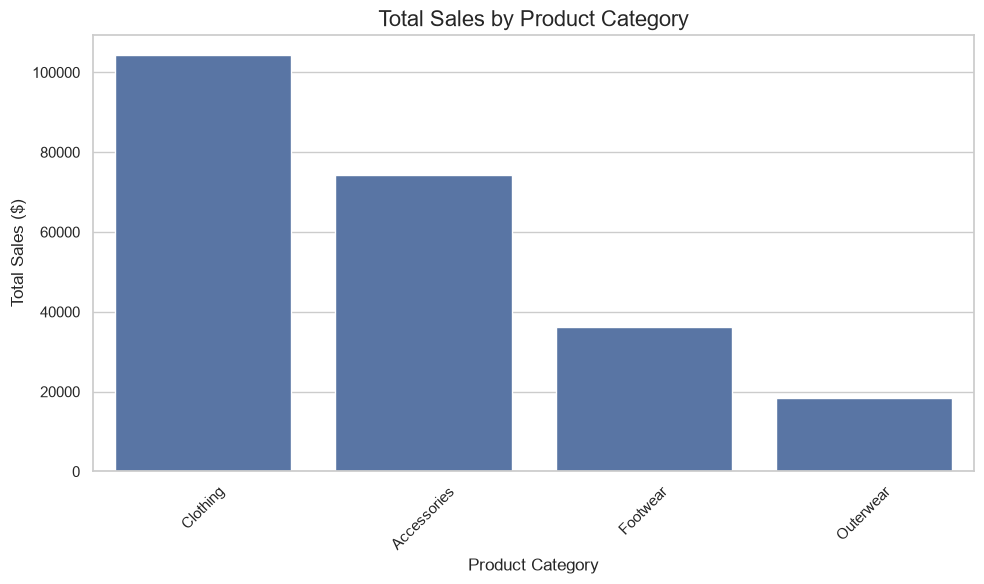

In [32]:
# Category wise total sales
category_sales = df.groupby("category")["purchase_amount"].sum().reset_index()

# Sales ko descending order mein arrange karein
category_sales = category_sales.sort_values(
    by="purchase_amount", ascending=False
)

# Graph banayein
plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_sales,
    x="category",
    y="purchase_amount"
)

plt.title("Total Sales by Product Category", fontsize=16)
plt.xlabel("Product Category")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

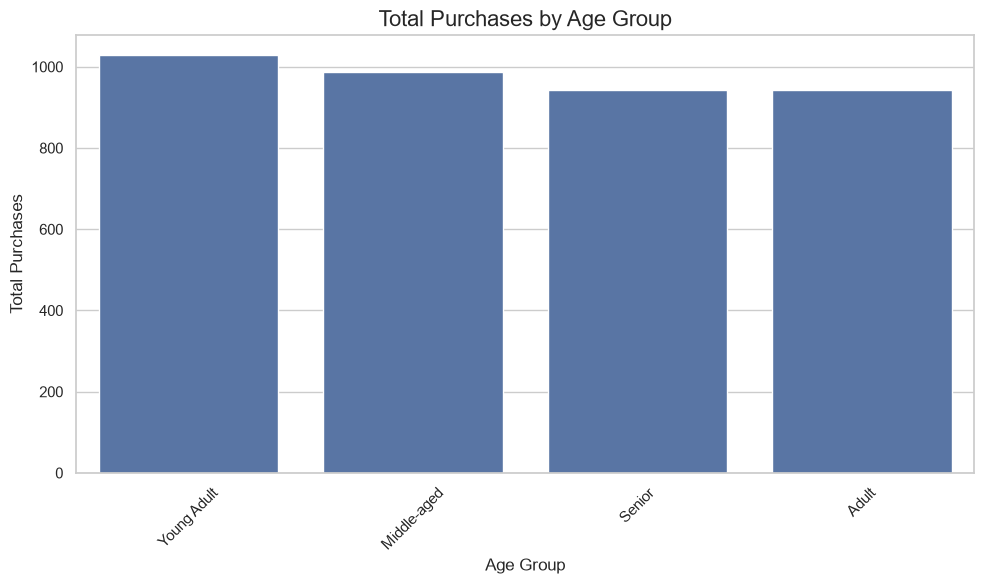

In [33]:
# Age group wise purchases
age_purchases = df["age_group"].value_counts().reset_index()

age_purchases.columns = ["age_group", "total_purchases"]

plt.figure(figsize=(10, 6))

sns.barplot(
    data=age_purchases,
    x="age_group",
    y="total_purchases"
)

plt.title("Total Purchases by Age Group", fontsize=16)
plt.xlabel("Age Group")
plt.ylabel("Total Purchases")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

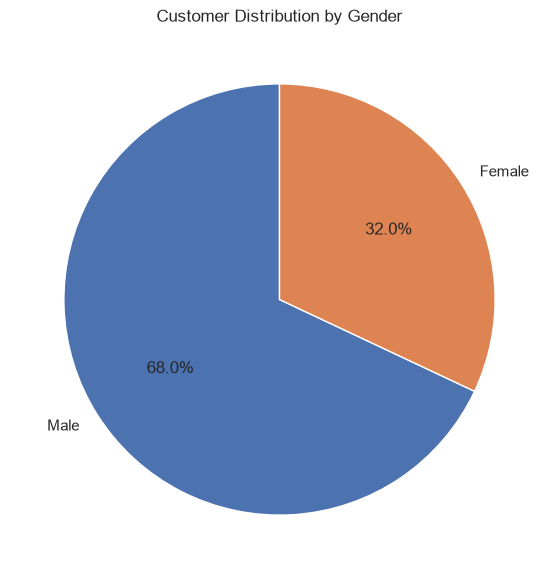

In [34]:
gender_count = df["gender"].value_counts().reset_index()
gender_count.columns = ["gender", "total_customers"]

plt.figure(figsize=(7, 7))

plt.pie(
    gender_count["total_customers"],
    labels=gender_count["gender"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Customer Distribution by Gender")
plt.show()

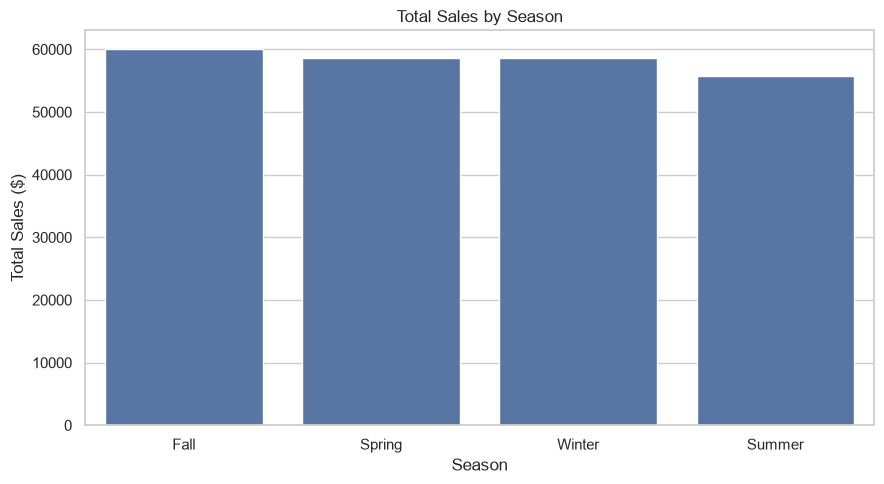

In [35]:
season_sales = df.groupby("season")["purchase_amount"].sum().reset_index()

season_sales = season_sales.sort_values(
    by="purchase_amount", ascending=False
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=season_sales,
    x="season",
    y="purchase_amount"
)

plt.title("Total Sales by Season")
plt.xlabel("Season")
plt.ylabel("Total Sales ($)")

plt.tight_layout()
plt.show()

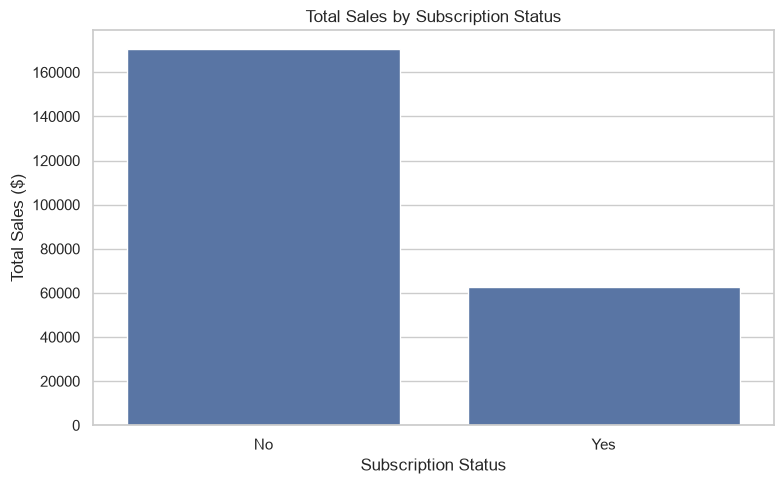

In [36]:
subscription_sales = df.groupby(
    "subscription_status"
)["purchase_amount"].sum().reset_index()

plt.figure(figsize=(8, 5))

sns.barplot(
    data=subscription_sales,
    x="subscription_status",
    y="purchase_amount"
)

plt.title("Total Sales by Subscription Status")
plt.xlabel("Subscription Status")
plt.ylabel("Total Sales ($)")

plt.tight_layout()
plt.show()

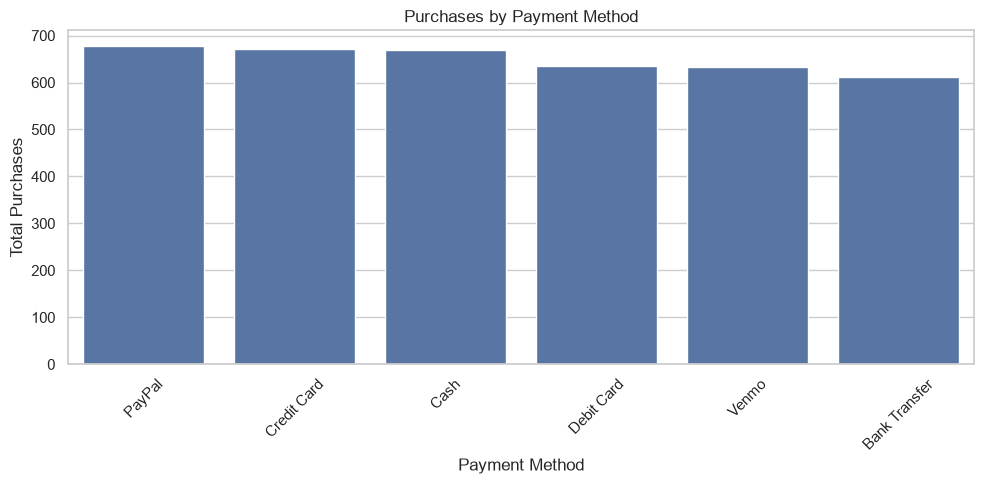

In [37]:
payment_count = df["payment_method"].value_counts().reset_index()

payment_count.columns = ["payment_method", "total_purchases"]

plt.figure(figsize=(10, 5))

sns.barplot(
    data=payment_count,
    x="payment_method",
    y="total_purchases"
)

plt.title("Purchases by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Purchases")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

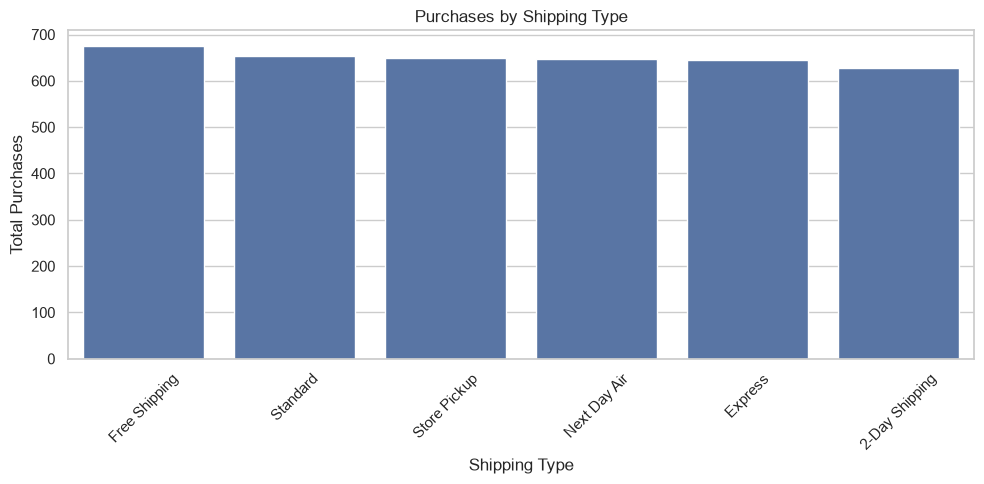

In [38]:
shipping_count = df["shipping_type"].value_counts().reset_index()

shipping_count.columns = ["shipping_type", "total_purchases"]

plt.figure(figsize=(10, 5))

sns.barplot(
    data=shipping_count,
    x="shipping_type",
    y="total_purchases"
)

plt.title("Purchases by Shipping Type")
plt.xlabel("Shipping Type")
plt.ylabel("Total Purchases")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

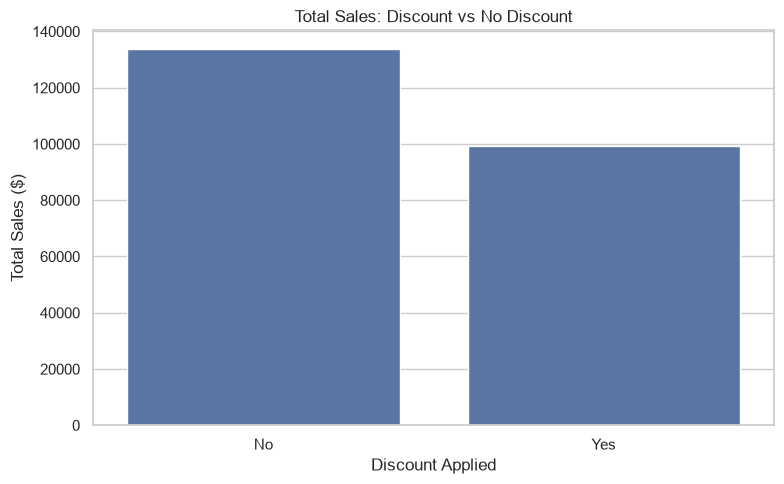

In [39]:
discount_sales = df.groupby(
    "discount_applied"
)["purchase_amount"].sum().reset_index()

plt.figure(figsize=(8, 5))

sns.barplot(
    data=discount_sales,
    x="discount_applied",
    y="purchase_amount"
)

plt.title("Total Sales: Discount vs No Discount")
plt.xlabel("Discount Applied")
plt.ylabel("Total Sales ($)")

plt.tight_layout()
plt.show()

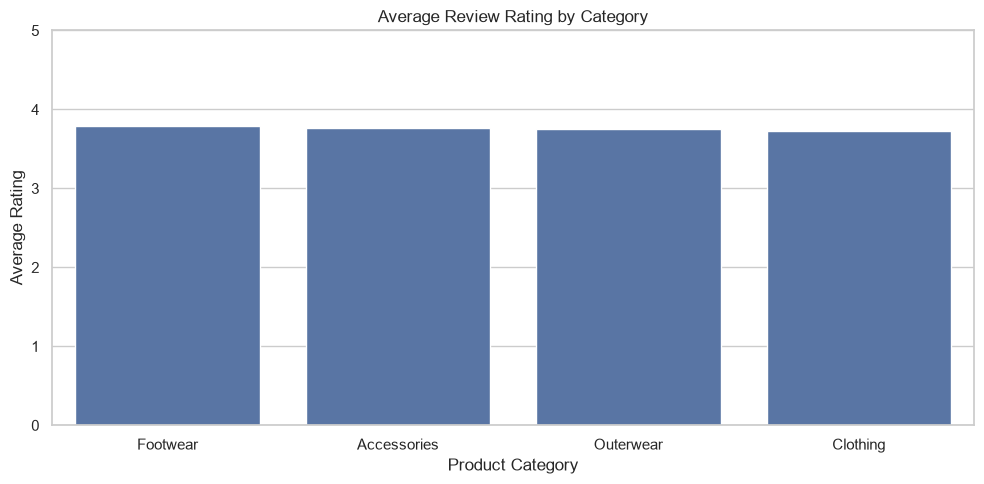

In [40]:
category_rating = df.groupby(
    "category"
)["review_rating"].mean().reset_index()

category_rating = category_rating.sort_values(
    by="review_rating", ascending=False
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=category_rating,
    x="category",
    y="review_rating"
)

plt.title("Average Review Rating by Category")
plt.xlabel("Product Category")
plt.ylabel("Average Rating")
plt.ylim(0, 5)

plt.tight_layout()
plt.show()

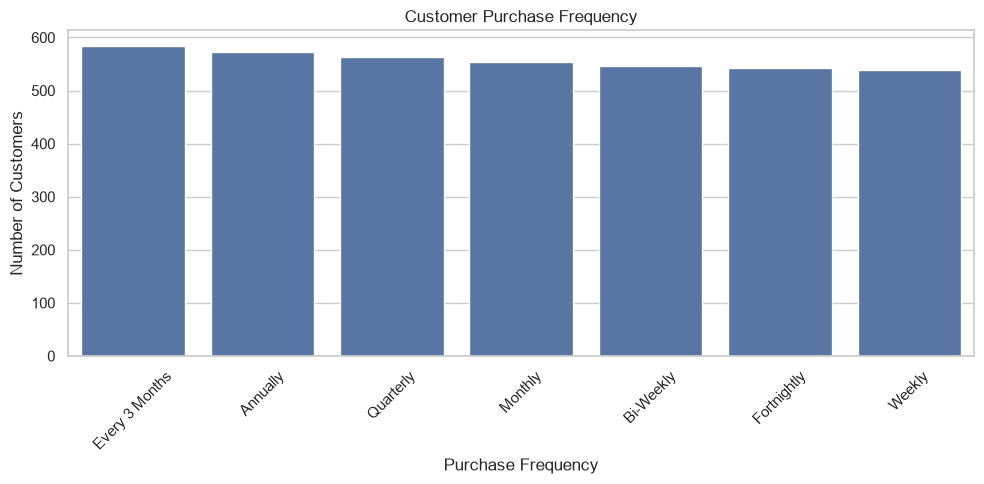

In [42]:
frequency_count = df["frequency_of_purchases"].value_counts().reset_index()

frequency_count.columns = ["purchase_frequency", "total_customers"]

plt.figure(figsize=(10, 5))

sns.barplot(
    data=frequency_count,
    x="purchase_frequency",
    y="total_customers"
)

plt.title("Customer Purchase Frequency")
plt.xlabel("Purchase Frequency")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

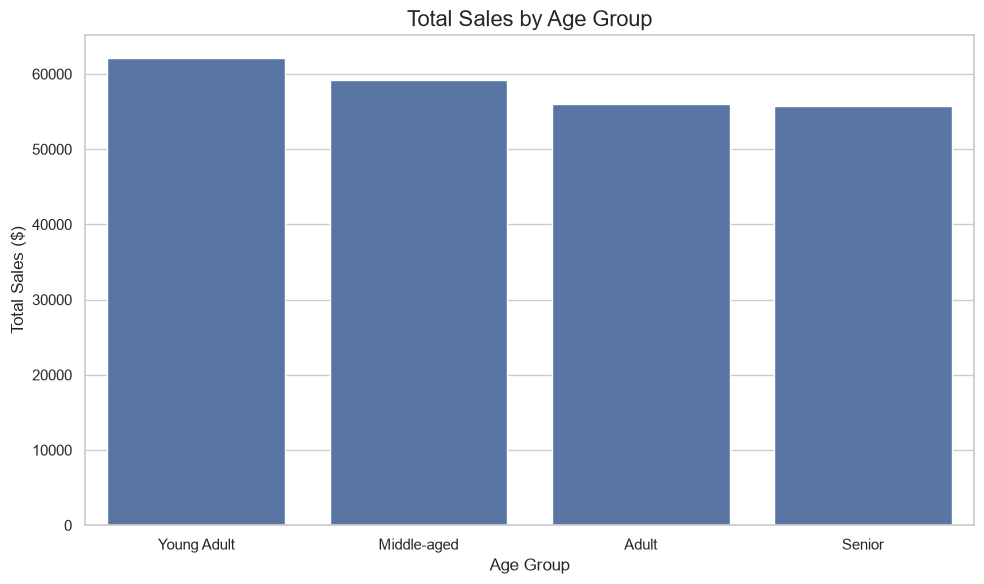

In [43]:
# Age group wise total sales
age_sales = df.groupby("age_group")["purchase_amount"].sum().reset_index()

# Highest sales first
age_sales = age_sales.sort_values(
    by="purchase_amount", ascending=False
)

# Create graph
plt.figure(figsize=(10, 6))

sns.barplot(
    data=age_sales,
    x="age_group",
    y="purchase_amount"
)

plt.title("Total Sales by Age Group", fontsize=16)
plt.xlabel("Age Group")
plt.ylabel("Total Sales ($)")

plt.tight_layout()
plt.show()

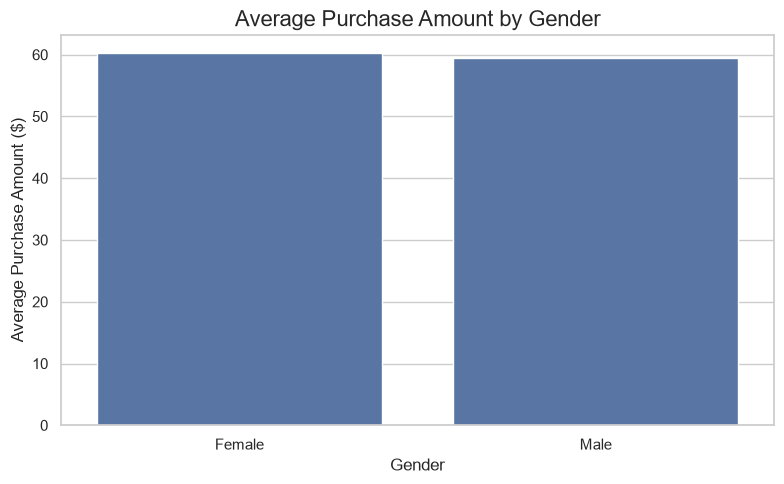

In [44]:
# Gender wise average purchase amount
gender_avg = df.groupby("gender")["purchase_amount"].mean().reset_index()

# Create graph
plt.figure(figsize=(8, 5))

sns.barplot(
    data=gender_avg,
    x="gender",
    y="purchase_amount"
)

plt.title("Average Purchase Amount by Gender", fontsize=16)
plt.xlabel("Gender")
plt.ylabel("Average Purchase Amount ($)")

plt.tight_layout()
plt.show()

In [45]:
# Cleaned DataFrame ko CSV mein save karein
df.to_csv("customer_shopping_cleaned.csv", index=False)

print("Cleaned dataset successfully saved!")

Cleaned dataset successfully saved!


In [46]:
print("Dataset Shape:", df.shape)

print("Is DataFrame Empty?", df.empty)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (3900, 19)
Is DataFrame Empty? False

Missing Values:
customer_id                0
age                        0
gender                     0
item_purchased             0
category                   0
purchase_amount            0
location                   0
size                       0
color                      0
season                     0
review_rating              0
subscription_status        0
shipping_type              0
discount_applied           0
previous_purchases         0
payment_method             0
frequency_of_purchases     0
age_group                  0
purchase_frequency_days    0
dtype: int64

Duplicate Rows: 0

Data Types:
customer_id                  int64
age                          int64
gender                         str
item_purchased                 str
category                       str
purchase_amount              int64
location                       str
size                           str
color                          str
season              